# Max-Clique Benchmarking for OQI: From Classical to Molecular Graphs

## Overview
This notebook benchmarks various Max-Clique algorithms (Exact, Greedy, Local Search, and Quantum-Inspired FEM) across three distinct domains to establish a baseline for Quantum Advantage:

1.  **Standard DIMACS Benchmarks**: Traditional computer science graph problems.
2.  **Synthetic Molecular Graphs**: Generated graphs that mimic molecular docking properties (Naive & Realistic variants).
3.  **Real-World Molecular Case**: A graph constructed from the 2OI0 Protein-Ligand complex.

---

In [1]:
import os
import sys
import time
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Import the classical solver logic
# Ensure max_clique_classical.py is in the same directory
import max_clique_classical as solver

In [2]:
# ==========================================
# Helper Function: Visualization
# ==========================================
def plot_benchmark_results(results, title="Benchmark Results"):
    """
    Visualizes the Size and Time of different methods side-by-side.
    """
    df = pd.DataFrame(results)
    
    # Filter out failed runs for plotting
    df['size'] = df['size'].astype(int)
    df['time'] = df['time'].astype(float)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Plot 1: Clique Size (Accuracy)
    # 這裡通常不需要改，因為 hue 已經被用在 'is_valid' 上了
    sns.barplot(data=df, x='method', y='size', hue='is_valid', palette='viridis', ax=ax1)
    ax1.set_title(f"{title} - Clique Size (Higher is Better)")
    ax1.set_ylabel("Clique Size")
    
    # 加上數值標籤 (需確認 matplotlib 版本支援 bar_label，若報錯可註解掉)
    if hasattr(ax1, 'containers'): 
        for container in ax1.containers:
            ax1.bar_label(container)
    
    # Plot 2: Execution Time (Speed)
    # [FIX] 明確指定 hue 並關閉 legend 以消除警告
    sns.barplot(data=df, x='method', y='time', hue='method', palette='magma', legend=False, ax=ax2)
    ax2.set_title(f"{title} - Execution Time (Lower is Better)")
    ax2.set_ylabel("Time (seconds)")
    ax2.set_yscale('log') # Log scale often helps if Exact method is slow
    
    plt.tight_layout()
    plt.show()

## Part 1: Standard DIMACS Benchmarking
We start by testing the solvers on standard benchmark graphs (e.g., `brock`, `c-fat`). This validates that the solvers are working correctly on known hard problems.

Running Benchmark on c-fat200-1.mtx...

solve: c-fat200-1

 graph properties:
  name: c-fat200-1
  n_nodes: 200
  n_edges: 1534
  density: 0.0770854271356784
  avg_degree: 15.34
  max_degree: 17
  min_degree: 14
  max_possible_clique: 55

[1/4] Solving using the FEM...
FEM solving:
  try origin_func
    results: value=10, valid=True
  try balance_func
    results: value=12, valid=True
  try degree_func
    results: value=10, valid=True
  FEM compare:
    origin_func: value=10, valid=True
    balance_func: value=12, valid=True
    degree_func: value=10, valid=True
  final choice: balance_func
  FEM results: value=12, valid=True, time=11.97s

[2/4] Solving using the Exact...
  Exact results: value=12, time=0.00s

[3/4] Solving using the Greedy...
  Greedy results: value=12, valid=True, time=0.00s

[4/4] Solving using the Local search...
  Local search results: value=12, valid=True, time=0.42s

summary:
best result: FEM - value=12

 Table:
  FEM                  | solution:  12 | valid | 

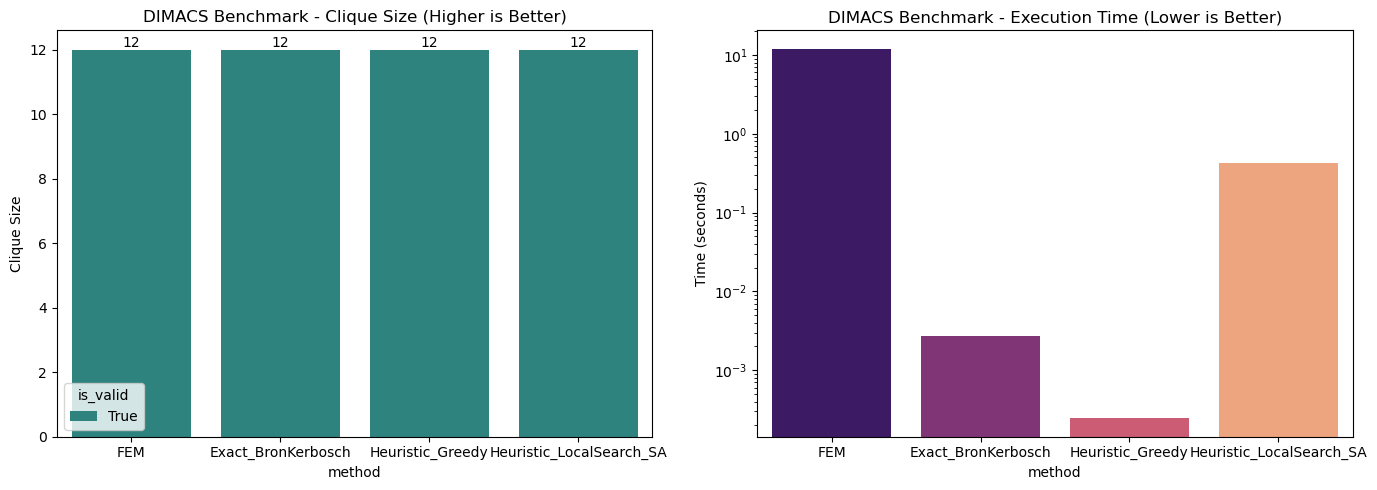

In [3]:
# Define path to a standard DIMACS file
# Replace with an actual path on your machine, or we can skip if file not found
dimacs_path = "/home/kesson/OQI/max_clique_graph_benchmark/c-fat200-1.mtx"

if os.path.exists(dimacs_path):
    print(f"Running Benchmark on {os.path.basename(dimacs_path)}...")
    
    # Calling the unified solver from your script
    results_dimacs, props_dimacs = solver.solve_max_clique_unified(
        dimacs_path, 
        methods=['Greedy', 'LocalSearch', 'FEM', 'Exact']
    )
    
    plot_benchmark_results(results_dimacs, title="DIMACS Benchmark")
else:
    print("DIMACS file not found. Skipping Part 1.")

## Part 2: Synthetic Molecular Graphs

Real molecular docking graphs have specific structures (semi-sparse, modular). We generate two types:
1.  **Naive**: Random graph with a planted clique ($K_\omega$).
2.  **Realistic**: Graph based on 3D latent space embeddings with "Decoy" cliques (local optima traps).

In [4]:
import random
from scipy.spatial.distance import pdist, squareform

# ==========================================
# Generator 1: Naive Planted Clique
# ==========================================
def generate_naive_graph(target_n=600, target_omega=110, target_density=0.3, seed=42):
    """Generates a graph with a planted clique and random edges (SBM-like)."""
    random.seed(seed)
    np.random.seed(seed)
    G = nx.Graph()
    
    # 1. Plant the Clique
    clique_nodes = list(range(target_omega))
    G.add_nodes_from(range(target_n))
    for i in range(target_omega):
        for j in range(i+1, target_omega):
            G.add_edge(i, j)
            
    # 2. Add background noise to reach density
    current_m = G.number_of_edges()
    target_m = int(target_density * target_n * (target_n - 1) / 2)
    
    possible_edges = [(u, v) for u in range(target_n) for v in range(u+1, target_n) 
                      if not (u < target_omega and v < target_omega)]
    
    edges_to_add = target_m - current_m
    if edges_to_add > 0:
        chosen_edges = random.sample(possible_edges, edges_to_add)
        G.add_edges_from(chosen_edges)
        
    return G, "Naive_Planted_Clique"

# ==========================================
# Generator 2: Realistic Geometric + Decoys
# ==========================================
def generate_realistic_graph(n_nodes=600, target_density=0.3, clique_size=110, seed=42):
    """
    Generates a graph based on 3D latent space with Decoy cliques 
    to mimic local optima in docking.
    """
    np.random.seed(seed)
    random.seed(seed)
    
    # 1. Latent Space Embedding
    positions = np.random.rand(n_nodes, 3)
    dist_matrix = squareform(pdist(positions))
    
    # 2. Geometric Thresholding
    sorted_dists = np.sort(dist_matrix.flatten())
    sorted_dists = sorted_dists[sorted_dists > 0]
    threshold_idx = int(target_density * len(sorted_dists))
    distance_threshold = sorted_dists[threshold_idx]
    
    adj_matrix = np.zeros((n_nodes, n_nodes), dtype=np.int8)
    adj_matrix[dist_matrix < distance_threshold] = 1
    np.fill_diagonal(adj_matrix, 0)
    
    # 3. Implant Max Clique (Ground Truth)
    # Using spatially clustered nodes for realism
    clique_nodes = list(range(clique_size)) # Simplified: just take first N for now
    for i in range(len(clique_nodes)):
        for j in range(i + 1, len(clique_nodes)):
            u, v = clique_nodes[i], clique_nodes[j]
            adj_matrix[u, v] = adj_matrix[v, u] = 1

    # 4. Implant Decoys (False Positives)
    # High density blocks that are NOT the max clique
    n_decoys = 3
    decoy_size = int(clique_size * 0.7)
    current_idx = clique_size
    
    for _ in range(n_decoys):
        if current_idx + decoy_size < n_nodes:
            decoy_nodes = list(range(current_idx, current_idx + decoy_size))
            for i in range(len(decoy_nodes)):
                for j in range(i + 1, len(decoy_nodes)):
                    if random.random() < 0.95: # 95% density
                        u, v = decoy_nodes[i], decoy_nodes[j]
                        adj_matrix[u, v] = adj_matrix[v, u] = 1
            current_idx += decoy_size

    G = nx.from_numpy_array(adj_matrix)
    return G, "Realistic_Geometric_Decoys"

Generated Naive_Planted_Clique: Nodes=600, Edges=53910
Generated Realistic_Geometric_Decoys: Nodes=600, Edges=63937


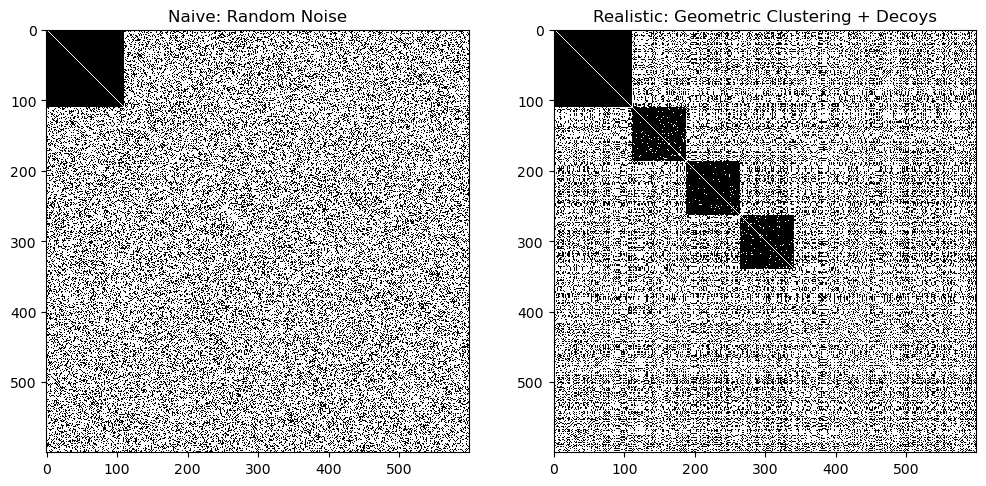


Benchmarking Realistic_Geometric_Decoys...


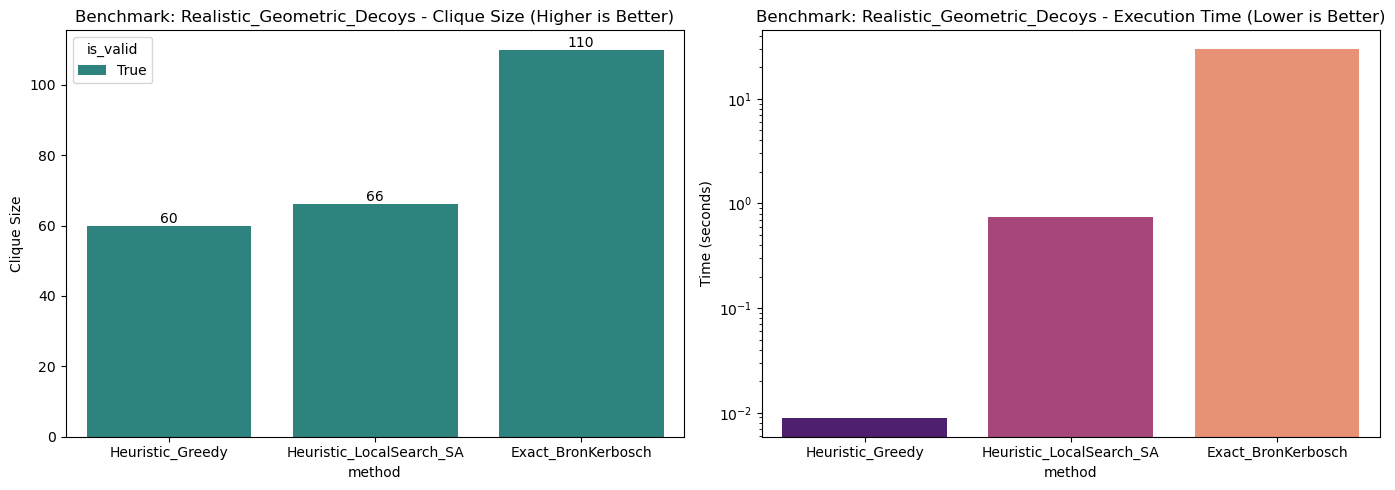

In [5]:
# === Generate and Benchmark Synthetic Graphs ===

# Parameters
N = 600
OMEGA = 110  # Increased to match typical benchmark size
DENSITY = 0.3

# 1. Generate Graphs
# Fix: Use keyword arguments to avoid positional mismatch
G_naive, name_naive = generate_naive_graph(
    target_n=N, 
    target_omega=OMEGA, 
    target_density=DENSITY
)

G_real, name_real = generate_realistic_graph(
    n_nodes=N, 
    target_density=DENSITY,  # Pass Density here (0.3)
    clique_size=OMEGA        # Pass Omega here (110)
)

print(f"Generated {name_naive}: Nodes={G_naive.number_of_nodes()}, Edges={G_naive.number_of_edges()}")
print(f"Generated {name_real}: Nodes={G_real.number_of_nodes()}, Edges={G_real.number_of_edges()}")

# 2. Visualize Matrix Structure (Comparison)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
ax1.imshow(nx.to_numpy_array(G_naive), cmap='Greys', interpolation='none')
ax1.set_title("Naive: Random Noise")
ax2.imshow(nx.to_numpy_array(G_real), cmap='Greys', interpolation='none')
ax2.set_title("Realistic: Geometric Clustering + Decoys")
plt.show()

# 3. Run Benchmark on Realistic Graph
print(f"\nBenchmarking {name_real}...")

results_real = []

# Greedy
h_solver = solver.HeuristicMaxClique(G_real)
results_real.append(h_solver.greedy_heuristic())

# Local Search
results_real.append(h_solver.local_search(max_iter=2000))

# Exact (with timeout protection)
ex_solver = solver.ExactMaxClique(G_real)
ex_solver.timeout = 30 
results_real.append(ex_solver.solve())

plot_benchmark_results(results_real, title=f"Benchmark: {name_real}")

## Part 3: Real-World Case (2OI0)
Here we construct the graph directly from the `2OI0.pdb` file using the Pharmacophore Interaction method. This represents the actual problem we aim to solve with quantum algorithms.

1. Loading Protein-Ligand Complex (2OI0)...
   -> Ligand Atoms: 20, Receptor Atoms: 2109
2. Extracting Pharmacophore Features...
   -> Features: Ligand=11, Receptor(near)=224
3. Building Interaction Graph...
   -> Graph Created: Nodes=68, Edges=544
   -> Saved to tace_max_clique.clq

4. Running Benchmark on Real-World Graph...
   Graph Properties: {'name': '2OI0_Protein_Ligand', 'n_nodes': 68, 'n_edges': 544, 'density': 0.23880597014925373, 'avg_degree': 16.0, 'max_degree': 32, 'min_degree': 2, 'max_possible_clique': 33}

solve: tace_max_clique

 graph properties:
  name: tace_max_clique
  n_nodes: 68
  n_edges: 544
  density: 0.23880597014925373
  avg_degree: 16.0
  max_degree: 32
  min_degree: 2
  max_possible_clique: 33

[2/3] Solving using the Exact...
  Exact results: value=9, time=0.00s

[3/3] Solving using the Greedy...
  Greedy results: value=6, valid=True, time=0.00s

[4/3] Solving using the Local search...
  Local search results: value=8, valid=True, time=0.19s

summary:
best

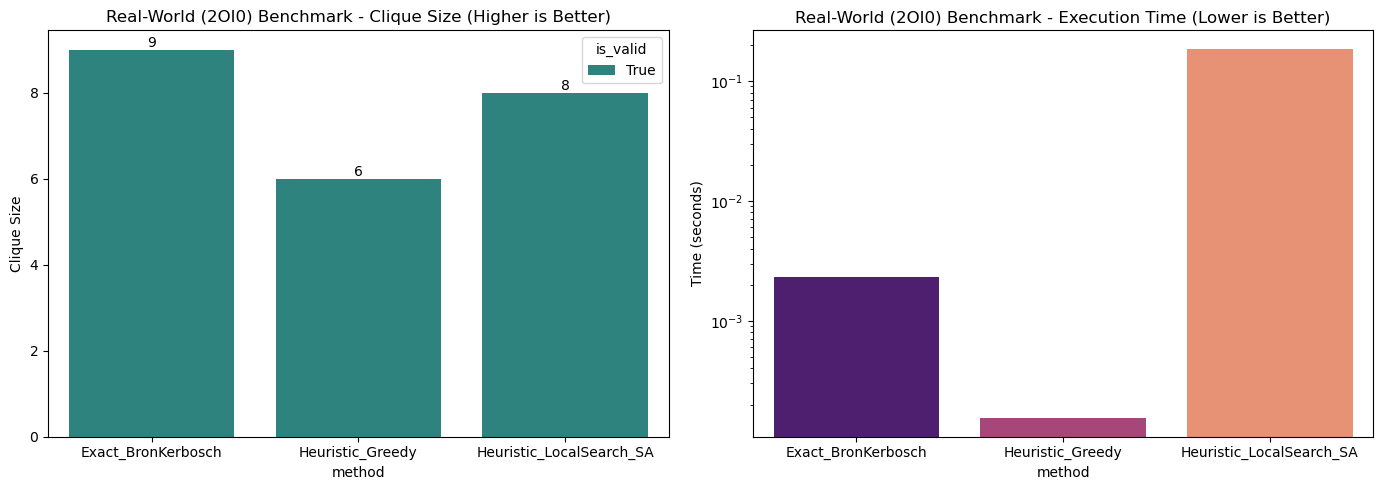

In [21]:
import os
import urllib.request
import numpy as np
import networkx as nx
import pandas as pd
from rdkit import Chem, RDConfig
from rdkit.Chem import AllChem
from scipy.spatial.distance import cdist

# =============================================================================
# 1. SETUP & DATA LOADING
# =============================================================================
print("1. Loading Protein-Ligand Complex (2OI0)...")
pdb_file = "2OI0.pdb"
if not os.path.exists(pdb_file):
    print(f"   Downloading {pdb_file}...")
    urllib.request.urlretrieve("https://files.rcsb.org/download/2OI0.pdb", pdb_file)

complex_mol = Chem.MolFromPDBFile(pdb_file, removeHs=False, sanitize=False)

# =============================================================================
# 2. PRE-PROCESSING (Extract Ligand & Receptor)
# =============================================================================
# Helper function to safely extract sub-molecules
def extract_submol(original_mol, keep_indices):
    rw_mol = Chem.RWMol(original_mol)
    all_indices = set(range(rw_mol.GetNumAtoms()))
    keep_set = set(keep_indices)
    for idx in sorted(list(all_indices - keep_set), reverse=True):
        rw_mol.RemoveAtom(idx)
    new_mol = rw_mol.GetMol()
    try:
        Chem.SanitizeMol(new_mol)
    except:
        new_mol.UpdatePropertyCache(strict=False)
    return new_mol

# Identify Ligand vs Receptor atoms
ligand_atoms = []
receptor_atoms = []
for atom in complex_mol.GetAtoms():
    res_info = atom.GetPDBResidueInfo()
    if not res_info: continue
    res_name = res_info.GetResidueName().strip()
    is_hetero = res_info.GetIsHeteroAtom()
    
    if is_hetero and res_name not in ["HOH", "ZN"]:
        ligand_atoms.append(atom.GetIdx())
    elif res_name != "HOH": 
        receptor_atoms.append(atom.GetIdx())

ligand_mol = extract_submol(complex_mol, ligand_atoms)
receptor_mol = extract_submol(complex_mol, receptor_atoms)
print(f"   -> Ligand Atoms: {ligand_mol.GetNumAtoms()}, Receptor Atoms: {receptor_mol.GetNumAtoms()}")

# =============================================================================
# 3. FEATURE EXTRACTION (Pharmacophores)
# =============================================================================
print("2. Extracting Pharmacophore Features...")
fdefName = os.path.join(RDConfig.RDDataDir, 'BaseFeatures.fdef')
featFactory = AllChem.BuildFeatureFactory(fdefName)

fam_mapping = {
    'Donor': 'Donor', 'Acceptor': 'Acceptor',
    'NegIonizable': 'Negative', 'PosIonizable': 'Positive',
    'Aromatic': 'Aromatic', 'Hydrophobe': 'Hydrophobe',
    'LumpedHydrophobe': 'Hydrophobe', 'ZnBinder': 'ZnBinder'
}

def get_features(mol):
    raw_feats = featFactory.GetFeaturesForMol(mol)
    processed = []
    for f in raw_feats:
        if f.GetFamily() in fam_mapping:
            processed.append({
                'family': fam_mapping[f.GetFamily()],
                'pos': np.array(f.GetPos())
            })
    return processed

lig_feats = get_features(ligand_mol)
rec_feats_all = get_features(receptor_mol)

# Filter receptor features to be near the ligand (Optimization)
rec_pos = np.array([f['pos'] for f in rec_feats_all])
lig_pos = np.array([f['pos'] for f in lig_feats])
if len(rec_pos) > 0 and len(lig_pos) > 0:
    dists = cdist(rec_pos, lig_pos)
    keep_mask = np.min(dists, axis=1) < 10.0 # 10 Angstrom cutoff
    rec_feats = [rec_feats_all[i] for i in range(len(rec_feats_all)) if keep_mask[i]]
else:
    rec_feats = []

print(f"   -> Features: Ligand={len(lig_feats)}, Receptor(near)={len(rec_feats)}")

# =============================================================================
# 4. BUILD GRAPH (Interaction Nodes & Geometric Edges)
# =============================================================================
print("3. Building Interaction Graph...")
interaction_rules = {
    ('Donor', 'Acceptor'), ('Acceptor', 'Donor'),
    ('Negative', 'Positive'), ('Positive', 'Negative'),
    ('Hydrophobe', 'Hydrophobe'), ('Aromatic', 'Aromatic'),
    ('Aromatic', 'Hydrophobe'), ('Hydrophobe', 'Aromatic'),
    ('ZnBinder', 'ZnBinder')
}

nodes = []
for i, l in enumerate(lig_feats):
    for j, r in enumerate(rec_feats):
        if np.linalg.norm(l['pos'] - r['pos']) < 6.0: # Interaction distance
            if (l['family'], r['family']) in interaction_rules:
                nodes.append((i, j))

G_oqi = nx.Graph()
G_oqi.add_nodes_from(range(len(nodes)))
tolerance = 2.0 

for i in range(len(nodes)):
    for j in range(i + 1, len(nodes)):
        l1, r1 = nodes[i]
        l2, r2 = nodes[j]
        d_lig = np.linalg.norm(lig_feats[l1]['pos'] - lig_feats[l2]['pos'])
        d_rec = np.linalg.norm(rec_feats[r1]['pos'] - rec_feats[r2]['pos'])
        
        if abs(d_lig - d_rec) < tolerance:
            G_oqi.add_edge(i, j)

# Save to DIMACS format so our Unified Solver can read it standardly
oqi_graph_path = "tace_max_clique.clq"
with open(oqi_graph_path, 'w') as f:
    f.write(f"p edge {G_oqi.number_of_nodes()} {G_oqi.number_of_edges()}\n")
    for u, v in G_oqi.edges():
        f.write(f"e {u+1} {v+1}\n") # DIMACS is 1-based

print(f"   -> Graph Created: Nodes={G_oqi.number_of_nodes()}, Edges={G_oqi.number_of_edges()}")
print(f"   -> Saved to {oqi_graph_path}")

# =============================================================================
# 5. BENCHMARKING
# =============================================================================
print("\n4. Running Benchmark on Real-World Graph...")

# Analyze Properties
props = solver.analyze_graph_properties(G_oqi, "2OI0_Protein_Ligand")
print("   Graph Properties:", props)

# Run Benchmark
# Now the file exists, so solve_max_clique_unified will work
results_oqi, _ = solver.solve_max_clique_unified(
    oqi_graph_path, 
    methods=['Greedy', 'LocalSearch', 'Exact'] # Add 'FEM' if environment is ready
)

plot_benchmark_results(results_oqi, title="Real-World (2OI0) Benchmark")

In [25]:
# =============================================================================
# 6. MD PREPARATION (Kabsch Transformation & File Generation)
# =============================================================================
import numpy as np
from rdkit import Chem

def compute_transformation_matrix(src_points, dst_points):
    """
    Calculates the optimal rigid body transformation (Rotation R and Translation t)
    to align src_points (Ligand) to dst_points (Receptor) using the Kabsch algorithm.
    """
    assert len(src_points) == len(dst_points)
    
    # 1. Compute Centroids
    centroid_src = np.mean(src_points, axis=0)
    centroid_dst = np.mean(dst_points, axis=0)
    
    # 2. Center the points
    src_centered = src_points - centroid_src
    dst_centered = dst_points - centroid_dst
    
    # 3. Compute Covariance Matrix
    H = np.dot(src_centered.T, dst_centered)
    
    # 4. SVD to find Rotation
    U, S, Vt = np.linalg.svd(H)
    R = np.dot(Vt.T, U.T)
    
    # 5. Correction for Reflection (ensure right-handed coordinate system)
    if np.linalg.det(R) < 0:
        Vt[2, :] *= -1
        R = np.dot(Vt.T, U.T)
    
    # 6. Compute Translation
    t = centroid_dst - np.dot(centroid_src, R)
    return R, t

def generate_md_files(clique_result, nodes_map, lig_feats, rec_feats, ligand_mol, output_name="docked_ligand"):
    """
    Transforms the ligand coordinates based on the Max-Clique result and saves it to a PDB file.
    """
    # 1. Extract matched feature coordinates
    src_pts = [] # Ligand feature points
    dst_pts = [] # Receptor feature points
    
    print(f"   -> Transforming coordinates based on Clique Size={len(clique_result)}...")
    
    for node_idx in clique_result:
        # node_idx is the node ID in the graph
        # nodes_map[node_idx] gives (ligand_feature_index, receptor_feature_index)
        # Note: nodes_map corresponds to the 'nodes' list from Part 4
        l_idx, r_idx = nodes_map[node_idx]
        
        src_pts.append(lig_feats[l_idx]['pos'])
        dst_pts.append(rec_feats[r_idx]['pos'])
        
    src_pts = np.array(src_pts)
    dst_pts = np.array(dst_pts)
    
    if len(src_pts) < 3:
        print("   -> Warning: Less than 3 matching points. 3D alignment might be unstable!")
        
    # 2. Compute Transformation Matrix
    R, t = compute_transformation_matrix(src_pts, dst_pts)
    
    # 3. Apply transformation to the RDKit Mol object (Update all atom coordinates)
    # Create a copy to avoid modifying the original object
    new_mol = Chem.Mol(ligand_mol)
    conf = new_mol.GetConformer()
    
    for i in range(new_mol.GetNumAtoms()):
        pos_orig = np.array(conf.GetAtomPosition(i))
        # Formula: P_new = P_old * R + t
        pos_new = np.dot(pos_orig, R) + t
        conf.SetAtomPosition(i, list(pos_new))
        
    # 4. Save to file
    pdb_filename = f"{output_name}.pdb"
    Chem.MolToPDBFile(new_mol, pdb_filename)
    print(f"   -> ✅ PDB file generated: {pdb_filename} (Ready for Amber/GROMACS)")
    
    return new_mol

# =============================================================================
# Execution Block
# =============================================================================
print("\n5. Generating Coordinates for MD Simulation...")

# 1. Find the best solution from results_oqi
# Filter for valid results first
valid_results = [r for r in results_oqi if r['is_valid']]

if valid_results:
    # Select the result with the largest Clique Size
    best_result = max(valid_results, key=lambda x: x['size'])
    print(f"-> Selected Best Algorithm: {best_result['method']} (Size: {best_result['size']})")
    
    # 2. Generate Files
    # Note: 'nodes' comes from Part 4, 'lig_feats'/'rec_feats' from Part 3
    docked_mol = generate_md_files(
        clique_result=best_result['clique'], 
        nodes_map=nodes, 
        lig_feats=lig_feats, 
        rec_feats=rec_feats, 
        ligand_mol=ligand_mol,
        output_name="best_docked_pose"
    )
    
    # Optional: Visual check in notebook (2D)
    # from rdkit.Chem import Draw
    # display(Draw.MolToImage(docked_mol, size=(300, 300), caption="Docked Conformation"))
    
else:
    print("-> ❌ No valid clique found by any algorithm. Cannot generate MD files.")


5. Generating Coordinates for MD Simulation...
   -> Selected Best Algorithm: Exact_BronKerbosch (Size: 9)
   -> Transforming coordinates based on Clique Size=9...
   -> ✅ PDB file generated: best_docked_pose.pdb (Ready for Amber/GROMACS)


In [24]:
import py3Dmol

def visualize_docking_corrected(pdb_filename, ligand_code='283'):
    # 1. Read the PDB file
    try:
        with open(pdb_filename, "r") as f:
            pdb_data = f.read()
    except FileNotFoundError:
        return "Error: PDB file not found."

    # 2. Setup 3D Viewer
    view = py3Dmol.view(width=800, height=600)
    view.addModel(pdb_data, "pdb")
    
    # 3. Visualization Strategy: "Lock and Key"
    
    # [The Lock] Protein Receptor
    # Show as a gray, transparent surface to reveal the "Pocket" shape
    # 'opacity': 0.5 makes it semi-transparent so we can see the ligand inside
    view.addSurface(py3Dmol.VDW, 
                    {'opacity': 0.5, 'color': 'lightgray'}, 
                    {'protein': {}})
    
    # [The Key] Ligand (Use the detected code '283')
    # Show as distinct Red Sticks
    ligand_sel = {'resn': ligand_code}
    view.addStyle(ligand_sel, 
                  {'stick': {'colorscheme': 'redCarbon', 'radius': 0.4}})
    
    # [The Interactions] Nearby Residues
    # Highlight protein atoms within 5 Angstroms of the ligand
    # These are the "walls" of the pocket holding the ligand
    pocket_sel = {'within': {'distance': 5.0, 'sel': ligand_sel}, 'byres': True, 'molecule': 'protein'}
    view.addStyle(pocket_sel, 
                  {'stick': {'color': 'white', 'radius': 0.15}})

    # [Critical Anchor] Zinc Atom (ZN)
    # The ligand usually coordinates with this metal ion
    view.addStyle({'atom': 'ZN'}, 
                  {'sphere': {'scale': 1.0, 'color': 'purple'}})

    # 4. Zoom Camera to the Ligand (Crucial Step!)
    view.zoomTo(ligand_sel)
    
    return view

# Execute with the correct code found: '283'
print(f"Visualizing interaction for ligand: 283")
v = visualize_docking_corrected("2OI0.pdb", ligand_code='283')
v

Visualizing interaction for ligand: 283


3Dmol.js failed to load for some reason. Please check your browser console for error messages.